# LAB — Vision-Language Models: CLIP & LLaVA

**Module:** Artificial Intelligence / Generative AI  
**Level:** Phd Students  
**Environment:** Google Colab / Kaggle / Jupyter Notebook  
**Frameworks:** Python, PyTorch, Hugging Face Transformers

## Videos (Must see before Starting the Lab)
* https://www.youtube.com/watch?v=jXD6O93Ptks&t=6s
* https://www.youtube.com/watch?v=bK9ns4DkxQg&t=8s

## Objectives

This practical work introduces two important vision-language models:

- **CLIP**: image-text representation, similarity, zero-shot classification and image retrieval.
- **LLaVA**: multimodal image understanding and visual question answering.

At the end of the Lab, students should be able to:
1. Load a pretrained CLIP model.
2. Compare images and textual descriptions.
3. Perform zero-shot classification.
4. Evaluate classification accuracy.
5. Perform text-to-image retrieval.
6. Understand the architecture of LLaVA.
7. Run visual question answering.
8. Identify visual hallucinations.
9. Compare CLIP and LLaVA.
10. Build a small multimodal assistant.

> **Notebook organization:** Part I is the student statement. Part II contains the correction and reference implementations. Students should first complete the exercises without opening the correction section.

## Submission and rerun notes

This notebook contains the original recorded outputs and answers. For this submission copy, the input-loading cells in Exercises 2, 5, 7 and 8 were adapted to read the included files and `lab_data_manifest.json`. The experiments were not rerun after these packaging changes. Historical upload messages in saved outputs refer to the original Colab session.

**Environment:** Google Colab with an NVIDIA T4 GPU. Enable a GPU before running the LLaVA section. The original session used PyTorch 2.11.0+cu130, Transformers 5.18.0, Accelerate 1.15.0 and bitsandbytes 0.50.2. Loading LLaVA requires downloading approximately 14 GB of model files. Model weights are not included in this repository.

**To rerun in Colab:** upload `CLIP_LLaVA_final_data.zip` through the Files panel, then run this setup code in a new code cell before Exercise 1:

```python
from zipfile import ZipFile
with ZipFile("/content/CLIP_LLaVA_final_data.zip") as archive:
    archive.extractall("/content")
%cd /content
```

Then run the notebook in order. A local copy of the repository already contains the extracted data, but this notebook uses Colab-specific upload/download functions. The mini-project asks you to upload one image and enter a question. The bonus asks for a search query.

The VQA evaluation cell records the manual decisions made for the saved 25 responses. If you regenerate different responses, review the labels again before reporting accuracy.


# Part I — LAB STATEMENT

## Exercise 1 — Installation and model loading

Install the required libraries and load `openai/clip-vit-base-patch32`.

### Questions

**Q1.** What is CLIP?  
**Q2.** What are its two main components?  
**Q3.** What is the role of `CLIPProcessor`?  
**Q4.** What is the role of `CLIPModel`?

In [1]:
%pip install -q transformers torch torchvision pillow matplotlib pandas accelerate bitsandbytes

In [2]:
import torch
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from transformers import CLIPProcessor, CLIPModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

Device: cuda


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Q1. What is CLIP?
CLIP stands for Contrastive Language–Image Pretraining. It learns relationships between images and text so it can measure how well an image matches a description.

---


Q2. What are its two main components?
An image encoder and a text encoder. Both produce numerical representations called embeddings in a shared space, allowing them to be compared.

---


Q3. What is the role of CLIPProcessor?
It prepares the inputs: resizing and normalizing images, tokenizing text, and creating the tensors the model needs.

---


Q4. What is the role of CLIPModel?
It processes the prepared inputs, generates embeddings, and calculates image–text similarity scores.

## Exercise 2 — Load an image

Upload an image containing a recognizable object.

Examples: a cat, dog, car, horse, bird, airplane, person, etc.

### Questions

**Q5.** What is the size of the image?  
**Q6.** What type of data is stored in the PIL image object?

Saving brown cat.jpg to brown cat.jpg
Filename: brown cat.jpg
Image size: (514, 596)
Image mode: RGB


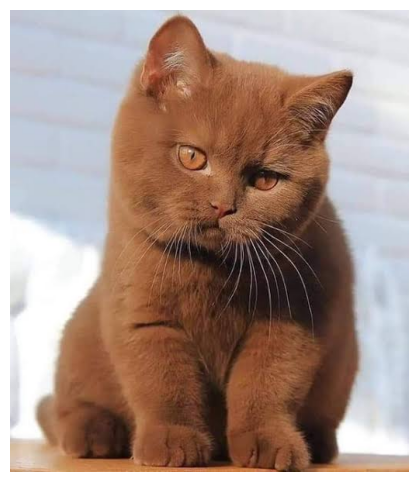

In [3]:
from pathlib import Path
import json

manifest_path = Path("lab_data_manifest.json")
if not manifest_path.is_file():
    raise FileNotFoundError(
        "Extract CLIP_LLaVA_final_data.zip in the current working directory first. "
        "See the setup instructions at the start of this notebook."
    )
lab_manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
IMAGE_PATH = lab_manifest["demo_image"]
image = Image.open(IMAGE_PATH).convert("RGB")
print("Filename:", IMAGE_PATH)
print("Image size:", image.size)
print("Image mode:", image.mode)
plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.show()


Q5. What is the size of the image?
My cat image is 514 pixels wide and 596 pixels high.

---


Q6. What type of data is stored in the PIL image object?
It contains the image’s pixel data. After conversion to RGB, each pixel has three colour values: red, green, and blue.

## Exercise 3 — Image/Text similarity

Use the following textual descriptions:

```python
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]
```

Calculate the CLIP image-text scores and convert them to probabilities.

### Questions

**Q7.** Which description has the highest probability?  
**Q8.** Is it compatible with the actual image?  
**Q9.** Why can CLIP compare an image with a sentence?  
**Q10.** What does `softmax()` do?

In [4]:
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]

inputs = processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True
)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

for text, probability in zip(texts, probs):
    print(f"{text:35s}: {probability.item():.4f}")

a photo of a cat                   : 0.9915
a photo of a dog                   : 0.0051
a photo of a car                   : 0.0001
a photo of a horse                 : 0.0007
a photo of a person                : 0.0026


Q7. Which description has the highest probability?
For my brown cat image, “a photo of a cat” received the highest value: 0.9915.

---


Q8. Is it compatible with the actual image?
Yes. The photograph clearly shows a cat, so the highest-scoring description matches its content.

---


Q9. Why can CLIP compare an image with a sentence?
Its image encoder and text encoder produce embeddings in a shared numerical space. CLIP learned to bring matching image–text representations closer together during training.

---


Q10. What does softmax() do?
It converts the matching scores into positive values that sum to 1. Here, they express the relative preference for each of the five descriptions.
That last distinction matters: 99.15% is relative to the descriptions supplied, rather than a guaranteed probability that the image contains a cat.

## Exercise 4 — Zero-shot classification

Implement:

```python
def classify_image(image, classes):
    ...
```

The function must return the predicted class and its probability.

### Questions

**Q11.** What is zero-shot classification?  
**Q12.** Why is it not necessary to train a new classifier?  
**Q13.** What happens if the correct class is not included in the candidate classes?

In [5]:
def classify_image(image, classes):
    descriptions = [f"a photo of a {name}" for name in classes]

    inputs = processor(
        text=descriptions,
        images=image,
        return_tensors="pt",
        padding=True
    )
    inputs = {key: value.to(device) for key, value in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)

    probabilities = outputs.logits_per_image.softmax(dim=1)[0]
    best_index = probabilities.argmax().item()

    return classes[best_index], probabilities[best_index].item()


classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

prediction, probability = classify_image(image, classes)

print("Prediction:", prediction)
print(f"Probability among candidate classes: {probability:.4f}")

Prediction: cat
Probability among candidate classes: 0.9937


Q11. What is zero-shot classification?
It means classifying an image into candidate categories without training the model on labeled examples of those categories for this task.

---


Q12. Why is it not necessary to train a new classifier?
CLIP’s pretrained image and text encoders already allow image–text comparisons. My function predicts a class by choosing the description that best matches the image.

---


Q13. What happens if the correct class is not included?
My function still selects one of the supplied classes, even if none is correct. For example, without “cat” in the list, it would choose another category for my cat photograph.

## Exercise 5 — Evaluate CLIP

Prepare at least 10 labeled images. For each image record:

- actual class;
- predicted class;
- probability;
- whether the prediction is correct.

Calculate:


$Accuracy = \frac{N_{correct}}{N_{total}}$


### Questions

**Q14.** What is the obtained accuracy?  
**Q15.** Which images are incorrectly classified?  
**Q16.** Give at least two possible reasons for the errors.

Use the following format:

```python
dataset = [
    ("cat1.jpg", "cat"),
    ("cat2.jpg", "cat"),
    ...
]
```

In [8]:
# The manifest preserves the original image-to-label correspondence.
evaluation_files = [row[0] for row in lab_manifest["evaluation_dataset"]]
print(f"Number of evaluation images: {len(evaluation_files)}")
for filename in evaluation_files:
    print(filename)


Saving b9bf23e0-4fd3-11ef-b8a6-c9027db4120d.jpg to b9bf23e0-4fd3-11ef-b8a6-c9027db4120d.jpg
Saving Petrusich-Dont-Mess-with-the-Birds.webp to Petrusich-Dont-Mess-with-the-Birds.webp
Saving Royal-Air-Maroc.jpg to Royal-Air-Maroc.jpg
Saving horse-3-768x501.jpg to horse-3-768x501.jpg
Saving ag_2600126051_bmw_7ser_campaign_prf_mms_3480x2160px1.avif to ag_2600126051_bmw_7ser_campaign_prf_mms_3480x2160px1.avif
Saving b1jft9l6p2gh1.jpg to b1jft9l6p2gh1.jpg
Saving Website_Blog_breed.jpg to Website_Blog_breed.jpg
Saving 66e930dea304a3e4b379e6b1_cpi-Amir-headshot.png to 66e930dea304a3e4b379e6b1_cpi-Amir-headshot.png
Saving Cat_November_2010-1a.jpg.webp to Cat_November_2010-1a.jpg.webp
Saving chocolate-british-shorthair-kitten-almontecats.com_.webp to chocolate-british-shorthair-kitten-almontecats.com_.webp

Number of uploaded images: 10
b9bf23e0-4fd3-11ef-b8a6-c9027db4120d.jpg
Petrusich-Dont-Mess-with-the-Birds.webp
Royal-Air-Maroc.jpg
horse-3-768x501.jpg
ag_2600126051_bmw_7ser_campaign_prf_mms_

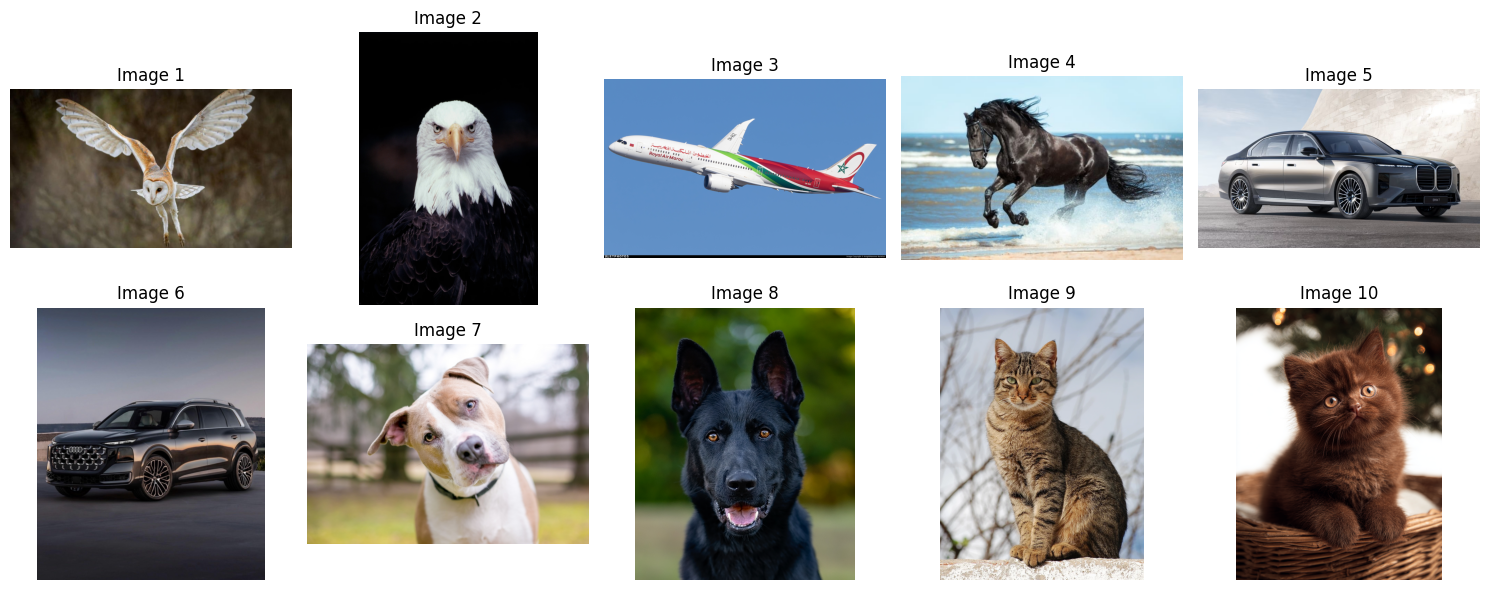

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for number, (ax, filename) in enumerate(
    zip(axes.flat, evaluation_files), start=1
):
    try:
        photo = Image.open(filename).convert("RGB")
        ax.imshow(photo)
    except Exception as error:
        ax.text(0.5, 0.5, "Could not open", ha="center")
        print(f"Image {number}: {error}")

    ax.set_title(f"Image {number}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [10]:
actual_labels = [
    "bird", "bird", "airplane", "horse", "car",
    "car", "dog", "dog", "cat", "cat"
]

dataset = list(zip(evaluation_files, actual_labels))
classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

results = []

for filename, actual_class in dataset:
    photo = Image.open(filename).convert("RGB")
    predicted_class, probability = classify_image(photo, classes)

    results.append({
        "Image": filename,
        "Actual class": actual_class,
        "Predicted class": predicted_class,
        "Probability": probability,
        "Correct": predicted_class == actual_class
    })

results_df = pd.DataFrame(results)
display(results_df.round({"Probability": 4}))

accuracy = results_df["Correct"].mean()
print(f"Accuracy: {accuracy:.2%}")
print(f"Correct predictions: {results_df['Correct'].sum()}/{len(dataset)}")

,Image,Actual class,Predicted class,Probability,Correct
0,b9bf23e0-4fd3-11ef-b8a6-c9027db4120d.jpg,bird,bird,0.9852,True
1,Petrusich-Dont-Mess-with-the-Birds.webp,bird,bird,0.9866,True
2,Royal-Air-Maroc.jpg,airplane,airplane,0.9624,True
3,horse-3-768x501.jpg,horse,horse,0.9995,True
4,ag_2600126051_bmw_7ser_campaign_prf_mms_3480x2...,car,car,0.9947,True
5,b1jft9l6p2gh1.jpg,car,car,0.9960,True
6,Website_Blog_breed.jpg,dog,dog,0.9892,True
7,66e930dea304a3e4b379e6b1_cpi-Amir-headshot.png,dog,dog,0.9863,True
8,Cat_November_2010-1a.jpg.webp,cat,cat,0.9968,True
9,chocolate-british-shorthair-kitten-almontecats...,cat,cat,0.9908,True


Accuracy: 100.00%
Correct predictions: 10/10


Q14. What is the obtained accuracy?
I obtained 100% accuracy, with 10 correct predictions out of 10 images. My dataset contains clear examples from six candidate classes.

---


Q15. Which images are incorrectly classified?
None. Every predicted class matched the label I assigned to the image.

---


Q16. Give at least two possible reasons for errors.
Although I observed no errors in this experiment, CLIP could make mistakes when:
- An object is small, partly hidden, blurred, or surrounded by a distracting background.
- The candidate descriptions are ambiguous or the correct class is missing.

## Exercise 6 — Prompt engineering with CLIP

Compare:

```python
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]
```

### Questions

**Q17.** Are the scores identical?  
**Q18.** Which prompt gives the highest score?  
**Q19.** What does this demonstrate about prompt formulation?

In [11]:
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]

inputs = processor(
    text=prompts,
    images=image,
    return_tensors="pt",
    padding=True
)
inputs = {key: value.to(device) for key, value in inputs.items()}

model.eval()

with torch.no_grad():
    outputs = model(**inputs)

scores = outputs.logits_per_image[0].float().cpu()

prompt_results = pd.DataFrame({
    "Prompt": prompts,
    "CLIP score": scores.tolist()
})

display(prompt_results.round({"CLIP score": 4}))

best_index = scores.argmax().item()
print("Highest-scoring prompt:", prompts[best_index])

,Prompt,CLIP score
0,a cat,27.2212
1,a photo of a cat,29.2936
2,a photograph showing a cat,28.6167
3,an image containing a cat,27.7462
4,a domestic animal called a cat,27.2604


Highest-scoring prompt: a photo of a cat


Q17. Are the scores identical?
No. For my brown cat image, the scores range from 27.2212 to 29.2936.

---


Q18. Which prompt gives the highest score?
“A photo of a cat” gives the highest score, 29.2936.

---


Q19. What does this demonstrate about prompt formulation?
My experiment shows that wording affects CLIP’s similarity scores, even when the descriptions have similar meanings. “A photo of a cat” worked best for this image, but I would need to test more images before concluding that it is generally the best wording.

# Part B — CLIP Image Retrieval

## Exercise 7 — Build an image database

Create a folder containing at least 20 images.

The images can represent animals, vehicles, people, buildings, landscapes, food or sports.

Calculate and store a normalized CLIP embedding for every image.

## Exercise 8 — Text-to-image retrieval

Use the query:

```text
"a person playing football"
```

Calculate its text embedding, compare it with all image embeddings, and display the five most similar images.

### Questions

**Q20.** What is the most similar image?  
**Q21.** Is it semantically relevant?  
**Q22.** Why does this method not require image labels?  
**Q23.** Give one real-world application of semantic image retrieval.

In [12]:
from pathlib import Path

IMAGE_DIR = Path("retrieval_images")
# First reproduce the original 20-image experiment without football photos.
retrieval_paths = [Path(path) for path in lab_manifest["retrieval_images"][:20]]
print(f"Loaded {len(retrieval_paths)} images.")
for number, path in enumerate(retrieval_paths, start=1):
    print(f"{number}. {path.name}")


Saving images (11).jpg to images (11).jpg
Saving images (10).jpg to images (10).jpg
Saving images (9).jpg to images (9).jpg
Saving images (8).jpg to images (8).jpg
Saving images (7).jpg to images (7).jpg
Saving images (6).jpg to images (6).jpg
Saving images (5).jpg to images (5).jpg
Saving images (4).jpg to images (4).jpg
Saving images (3).jpg to images (3).jpg
Saving images (2).jpg to images (2).jpg
Saving Brunch-Menu-Foxes-Love-Lemons-728x1094.jpg to Brunch-Menu-Foxes-Love-Lemons-728x1094.jpg
Saving delish-221219-burger-king-chicken-fries-0133-eb-1672788323.avif to delish-221219-burger-king-chicken-fries-0133-eb-1672788323.avif
Saving delish-202104-birriatacos-058-1665345202.avif to delish-202104-birriatacos-058-1665345202.avif
Saving GettyImages-2290758222_347734.jpg to GettyImages-2290758222_347734.jpg
Saving IIHF_Ice_Hockey_Women_20170405_08.jpg to IIHF_Ice_Hockey_Women_20170405_08.jpg
Saving images (1).jpg to images (1).jpg
Saving images.jpg to images.jpg
Saving b9bf23e0-4fd3-11e

In [13]:
QUERY = "a person playing football"

photos = [
    Image.open(path).convert("RGB")
    for path in retrieval_paths
]

inputs = processor(
    text=[QUERY],
    images=photos,
    return_tensors="pt",
    padding=True
)
inputs = {key: value.to(device) for key, value in inputs.items()}

model.eval()

with torch.no_grad():
    retrieval_outputs = model(**inputs)

image_embeddings = retrieval_outputs.image_embeds
text_embedding = retrieval_outputs.text_embeds


image_embeddings = image_embeddings / image_embeddings.norm(
    dim=1, keepdim=True
)
text_embedding = text_embedding / text_embedding.norm(
    dim=1, keepdim=True
)

torch.save(
    {
        "image_paths": [str(path) for path in retrieval_paths],
        "image_embeddings": image_embeddings.cpu()
    },
    "retrieval_index.pt"
)

print("Image embeddings:", image_embeddings.shape)
print("Query embedding:", text_embedding.shape)
print("Image index saved.")

Image embeddings: torch.Size([20, 512])
Query embedding: torch.Size([1, 512])
Image index saved.


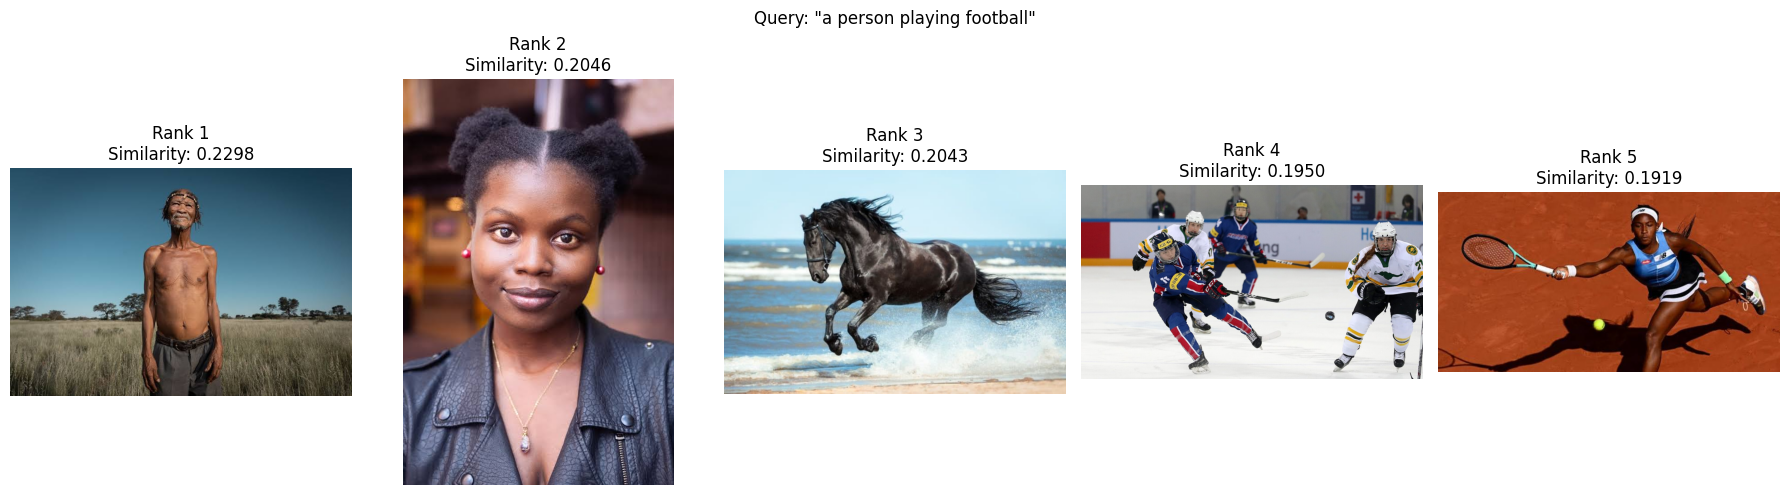

,Rank,Image,Cosine similarity
0,1,images (7).jpg,0.229751
1,2,images (5).jpg,0.204575
2,3,horse-3-768x501 (1).jpg,0.204260
3,4,IIHF_Ice_Hockey_Women_20170405_08.jpg,0.195041
4,5,images (1).jpg,0.191897


In [14]:
similarities = (image_embeddings @ text_embedding.T).squeeze(1)

top_scores, top_indices = similarities.topk(5)

fig, axes = plt.subplots(1, 5, figsize=(18, 5))
retrieval_results = []

for rank, (ax, index, score) in enumerate(
    zip(axes, top_indices.tolist(), top_scores.tolist()),
    start=1
):
    path = retrieval_paths[index]

    ax.imshow(photos[index])
    ax.set_title(f"Rank {rank}\nSimilarity: {score:.4f}")
    ax.axis("off")

    retrieval_results.append({
        "Rank": rank,
        "Image": path.name,
        "Cosine similarity": score
    })

fig.suptitle(f'Query: "{QUERY}"')
plt.tight_layout()
plt.show()

retrieval_results_df = pd.DataFrame(retrieval_results)
display(retrieval_results_df)

In [15]:
# Add the same two football images used in the recorded experiment.
retrieval_paths = [Path(path) for path in lab_manifest["retrieval_images"]]
print(f"Images now in the collection: {len(retrieval_paths)}")


Saving football.jpg to football.jpg
Saving Akam-Pelly20Mpanzu.webp to Akam-Pelly20Mpanzu.webp
Images now in the collection: 22


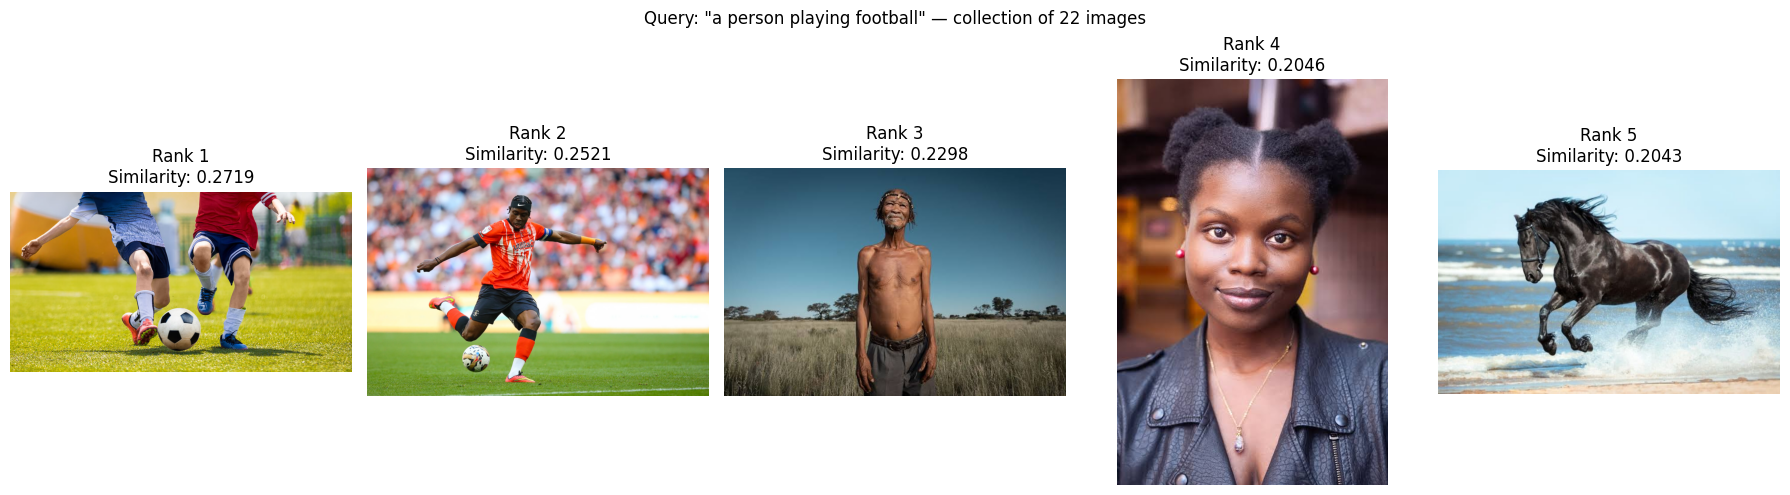

,Rank,Image,Cosine similarity
0,1,football_21.jpg,0.271945
1,2,football_22.webp,0.252136
2,3,images (7).jpg,0.229751
3,4,images (5).jpg,0.204575
4,5,horse-3-768x501 (1).jpg,0.204260


In [16]:
QUERY = "a person playing football"

photos = [
    Image.open(path).convert("RGB")
    for path in retrieval_paths
]

inputs = processor(
    text=[QUERY],
    images=photos,
    return_tensors="pt",
    padding=True
)
inputs = {key: value.to(device) for key, value in inputs.items()}

model.eval()

with torch.no_grad():
    search_outputs = model(**inputs)

image_embeddings = torch.nn.functional.normalize(
    search_outputs.image_embeds, dim=1
)
text_embedding = torch.nn.functional.normalize(
    search_outputs.text_embeds, dim=1
)

torch.save(
    {
        "image_paths": [str(path) for path in retrieval_paths],
        "image_embeddings": image_embeddings.cpu()
    },
    "retrieval_index.pt"
)

similarities = (image_embeddings @ text_embedding.T).squeeze(1)
top_scores, top_indices = similarities.topk(5)

fig, axes = plt.subplots(1, 5, figsize=(18, 5))
updated_results = []

for rank, (ax, index, score) in enumerate(
    zip(axes, top_indices.tolist(), top_scores.tolist()), start=1
):
    ax.imshow(photos[index])
    ax.set_title(f"Rank {rank}\nSimilarity: {score:.4f}")
    ax.axis("off")

    updated_results.append({
        "Rank": rank,
        "Image": retrieval_paths[index].name,
        "Cosine similarity": score
    })

fig.suptitle(f'Query: "{QUERY}" — collection of 22 images')
plt.tight_layout()
plt.show()

retrieval_results_after_df = pd.DataFrame(updated_results)
display(retrieval_results_after_df)

Q20. What is the most similar image?
The highest-ranked image is football_21.jpg, showing players with a football. Its cosine similarity to the query is approximately 0.2719.

---


Q21. Is it semantically relevant?
Yes. The first two results show football being played and match my query. The remaining three results do not show football, so the complete top-five list is only partly relevant.

---


Q22. Why does this method not require image labels?
CLIP’s pretrained encoders represent images and text in a shared embedding space. I can rank my images by similarity to the query without manually assigning class labels to the collection.

---


Q23. Give one real-world application of semantic image retrieval.
For my PhD project, it could help search an artwork collection using descriptions, such as “a painting showing a coastal landscape,” even when those exact words are absent from the filenames.

---

Observation : My original collection contained no football scenes, so none of the retrieved images fully matched the query. After I added two football photos, they became the top two results. This demonstrates that retrieval depends on what is available in the image collection.


In [17]:
import json
import zipfile
from pathlib import Path
from google.colab import files

tables = {
    "classification_results.csv": results_df,
    "prompt_comparison.csv": prompt_results,
    "retrieval_before.csv": retrieval_results_df,
    "retrieval_after.csv": retrieval_results_after_df
}

for filename, table in tables.items():
    table.to_csv(filename, index=False)

manifest = {
    "demo_image": str(IMAGE_PATH),
    "evaluation_dataset": dataset,
    "candidate_classes": classes,
    "retrieval_images": [str(path) for path in retrieval_paths],
    "query": QUERY
}

Path("lab_data_manifest.json").write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8"
)

backup_paths = list(dict.fromkeys(
    [Path(IMAGE_PATH)]
    + [Path(filename) for filename in evaluation_files]
    + [Path(path) for path in retrieval_paths]
    + [Path(filename) for filename in tables]
    + [Path("retrieval_index.pt"), Path("lab_data_manifest.json")]
))

for path in backup_paths:
    if not path.is_file():
        raise FileNotFoundError(f"Missing backup file: {path}")

with zipfile.ZipFile(
    "CLIP_lab_backup.zip", "w", zipfile.ZIP_DEFLATED
) as archive:
    for path in backup_paths:
        archive.write(path, arcname=path.as_posix())

print("Backup created successfully.")
files.download("CLIP_lab_backup.zip")

Backup created successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Part C — LLaVA

## Exercise 9 — Architecture

Complete:

```text
Image
  |
  v
CLIP Vision Encoder
  |
  v
______________
  |
  v
Language Model
  |
  v
Text Response
```

### Questions

**Q24.** What is the role of the vision encoder?  
**Q25.** Why is a projection layer required?  
**Q26.** What is the role of the language model?

Completed architecture:
Image → CLIP Vision Encoder → Projection Layer → Language Model → Text Response

---


Q24. What is the role of the vision encoder?
It extracts numerical features from the image that represent visual information, such as objects and their appearance.

---


Q25. Why is a projection layer required?
The vision encoder and language model use different feature representations. The projector maps visual features into the language model’s embedding space so they can be processed together with text.

---


Q26. What is the role of the language model?
It processes the question together with the projected visual features and generates a text response.

## Exercise 10 — Run LLaVA

Use a LLaVA-compatible model appropriate for your available GPU.

Give the model an image and ask:

1. What is happening in this image?
2. How many people are visible?
3. What objects can you identify?
4. Describe the image in detail.

Record the answers.

In [20]:
from transformers import (
    AutoProcessor,
    LlavaForConditionalGeneration,
    BitsAndBytesConfig
)

MODEL_ID = "llava-hf/llava-1.5-7b-hf"

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

processor_llava = AutoProcessor.from_pretrained(MODEL_ID)

llava = LlavaForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=quantization_config,
    dtype=torch.float16,
    device_map={"": 0},
    low_cpu_mem_usage=True,
    use_safetensors=True
)

processor_llava.patch_size = llava.config.vision_config.patch_size
processor_llava.vision_feature_select_strategy = (
    llava.config.vision_feature_select_strategy
)
processor_llava.num_additional_image_tokens = 1
processor_llava.tokenizer.padding_side = "left"

llava.eval()

print("LLaVA is ready.")
print("4-bit loading:", getattr(llava, "is_loaded_in_4bit", False))

processor_config.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/701 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/674 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/505 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

LLaVA is ready.
4-bit loading: True


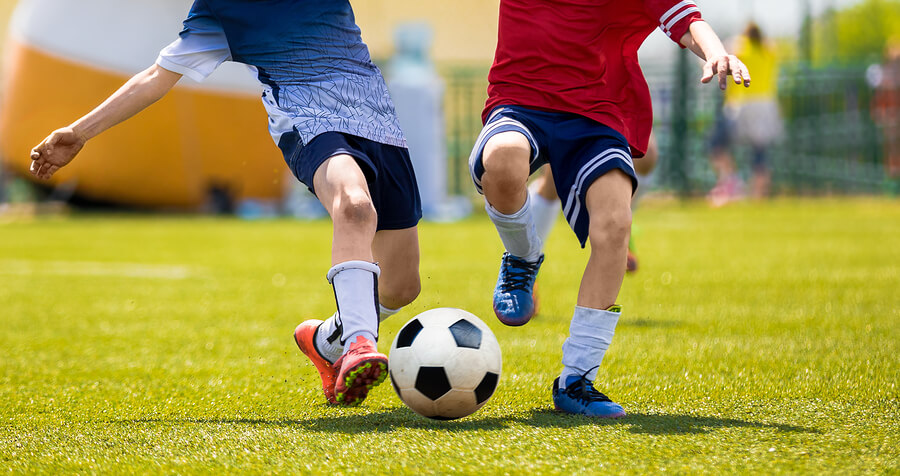

Question: What is happening in this image?
LLaVA answer: In the image, two young boys are playing soccer on a grassy field. They are both running towards the soccer ball, which is located in the middle of the field. The boys are actively engaged in the game, showcasing their athletic abilities and competitive spirit.


In [21]:
llava_image = Image.open(
    "retrieval_images/football_21.jpg"
).convert("RGB")

display(llava_image)


def ask_llava(picture, question, max_new_tokens=150):
    conversation = [
        {
            "role": "user",
            "content": [
                {"type": "image"},
                {"type": "text", "text": question}
            ]
        }
    ]

    prompt = processor_llava.apply_chat_template(
        conversation,
        add_generation_prompt=True
    )

    inputs = processor_llava(
        images=picture,
        text=prompt,
        return_tensors="pt"
    ).to(llava.device, torch.float16)

    with torch.inference_mode():
        generated_ids = llava.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False
        )

    answer_ids = generated_ids[0, inputs["input_ids"].shape[1]:]

    return processor_llava.decode(
        answer_ids,
        skip_special_tokens=True
    ).strip()


question = "What is happening in this image?"
answer = ask_llava(llava_image, question)

print("Question:", question)
print("LLaVA answer:", answer)

In [22]:
from textwrap import fill

exercise10_records = [{
    "Image": "retrieval_images/football_21.jpg",
    "Question": "What is happening in this image?",
    "LLaVA Answer": answer
}]

remaining_questions = [
    "How many people are visible?",
    "What objects can you identify?",
    "Describe the image in detail."
]

for current_question in remaining_questions:
    response = ask_llava(
        llava_image,
        current_question,
        max_new_tokens=200
    )

    exercise10_records.append({
        "Image": "retrieval_images/football_21.jpg",
        "Question": current_question,
        "LLaVA Answer": response
    })

    print("\nQuestion:", current_question)
    print(fill(response, width=100))

exercise10_results = pd.DataFrame(exercise10_records)
exercise10_results.to_csv("exercise10_llava_answers.csv", index=False)

print("\nAll four answers saved.")


Question: How many people are visible?
There are two people visible in the image.

Question: What objects can you identify?
In the image, you can identify a soccer ball and a pair of soccer cleats. The soccer ball is located
in the center of the scene, while the soccer cleats are positioned on the left side of the image.
These objects are likely part of a soccer game or practice session.

Question: Describe the image in detail.
The image captures a group of young boys playing soccer on a grassy field. There are at least five
boys actively participating in the game, with some of them running towards the soccer ball. The
soccer ball is located in the center of the field, surrounded by the boys.  In addition to the
players, there are two benches visible in the scene, one on the left side and the other on the right
side of the field. These benches may be used by the players when they are not actively engaged in
the game.

All four answers saved.


Note : I observed that LLaVA correctly counted two visible people when asked directly. However, its detailed description claimed there were at least five players and two benches, which the image does not clearly support. This shows why I need to check generated descriptions against the image, even when they sound convincing.

## Exercise 11 — Visual Question Answering

Choose five images. For each image ask five questions.

Example:

1. How many people are visible?
2. What objects can you see?
3. Where are the people?
4. What are they doing?
5. What is visible on the board?

Create a table containing:

| Image | Question | LLaVA Answer | Human Evaluation |
|---|---|---|---|

Calculate VQA accuracy:

\[
Accuracy = \frac{CorrectAnswers}{TotalQuestions}
\]

### Questions

**Q27.** What is the VQA accuracy?  
**Q28.** Which types of questions are difficult for LLaVA?

In [24]:
from pathlib import Path

matches = [
    str(path)
    for path in Path("/content").rglob("*")
    if path.is_file() and "royal" in path.name.lower()
]

print("Airplane files found:", matches)

Airplane files found: ['/content/Royal-Air-Maroc.jpg', '/content/Royal-Air-Maroc (1).jpg', '/content/retrieval_images/Royal-Air-Maroc (1).jpg']


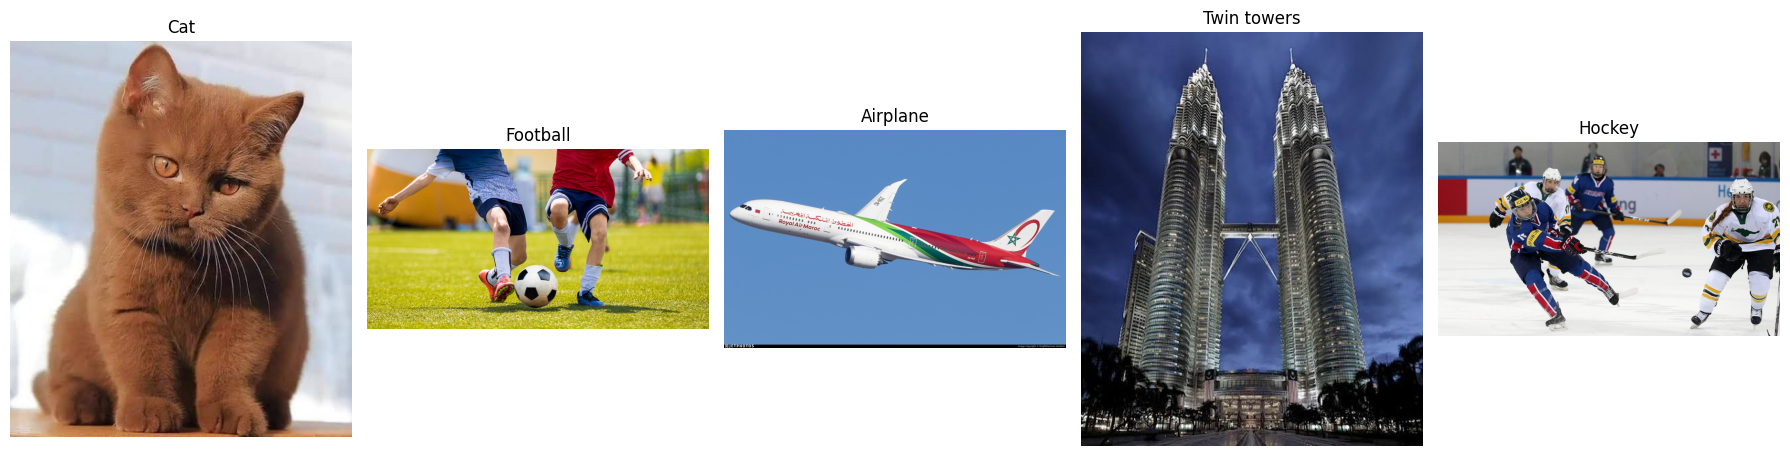

In [26]:
vqa_image_paths = {
    "Cat": str(IMAGE_PATH),
    "Football": "retrieval_images/football_21.jpg",
    "Airplane": "retrieval_images/Royal-Air-Maroc (1).jpg",
    "Twin towers": "retrieval_images/images (9).jpg",
    "Hockey": (
        "retrieval_images/"
        "IIHF_Ice_Hockey_Women_20170405_08.jpg"
    )
}

vqa_images = {}

fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for ax, (name, path) in zip(axes, vqa_image_paths.items()):
    picture = Image.open(path).convert("RGB")
    vqa_images[name] = picture

    ax.imshow(picture)
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [27]:
from google.colab import files

vqa_questions = {
    "Cat": [
        "What animal is shown?",
        "How many animals are visible?",
        "What is the main color of its fur?",
        "Is the animal sitting, standing, or lying down?",
        "What color are its eyes?"
    ],
    "Football": [
        "What sport is being played?",
        "How many foreground players are visible?",
        "What colors are on the ball?",
        "What surface are the players playing on?",
        "What color is the shirt of the player on the right?"
    ],
    "Airplane": [
        "What type of vehicle is shown?",
        "How many airplanes are visible?",
        "Is the airplane airborne or on the ground?",
        "What airline name is written on the airplane?",
        "What colors are visible on the airplane's tail?"
    ],
    "Twin towers": [
        "How many main towers are shown?",
        "What structure connects the two towers?",
        "Are the two main towers approximately the same height?",
        "What color is the sky?",
        "Are the tops of the towers flat or pointed?"
    ],
    "Hockey": [
        "What sport is being played?",
        "What surface are the players playing on?",
        "What equipment are the players holding?",
        "How many players are visible on the ice, excluding people behind the boards?",
        "What color is the puck?"
    ]
}

vqa_records = []

for image_name, questions in vqa_questions.items():
    for current_question in questions:
        response = ask_llava(
            vqa_images[image_name],
            current_question,
            max_new_tokens=128
        )

        vqa_records.append({
            "ID": len(vqa_records) + 1,
            "Image": image_name,
            "Question": current_question,
            "LLaVA Answer": response,
            "Human Evaluation": "",
            "Evaluation Note": ""
        })

        # Save progress after each answer.
        vqa_results = pd.DataFrame(vqa_records)
        vqa_results.to_csv("llava_vqa_results.csv", index=False)

        print(f"Completed {len(vqa_records)}/25: {image_name}")

print("\nAll 25 answers saved.")
files.download("llava_vqa_results.csv")

Completed 1/25: Cat
Completed 2/25: Cat
Completed 3/25: Cat
Completed 4/25: Cat
Completed 5/25: Cat
Completed 6/25: Football
Completed 7/25: Football
Completed 8/25: Football
Completed 9/25: Football
Completed 10/25: Football
Completed 11/25: Airplane
Completed 12/25: Airplane
Completed 13/25: Airplane
Completed 14/25: Airplane
Completed 15/25: Airplane
Completed 16/25: Twin towers
Completed 17/25: Twin towers
Completed 18/25: Twin towers
Completed 19/25: Twin towers
Completed 20/25: Twin towers
Completed 21/25: Hockey
Completed 22/25: Hockey
Completed 23/25: Hockey
Completed 24/25: Hockey
Completed 25/25: Hockey

All 25 answers saved.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
from textwrap import fill

for record in vqa_records:
    print(f"\n{record['ID']}. {record['Image']}")
    print("Question:", record["Question"])
    print("LLaVA answer:", fill(record["LLaVA Answer"], width=100))
    print("-" * 60)


1. Cat
Question: What animal is shown?
LLaVA answer: The image shows a cat.
------------------------------------------------------------

2. Cat
Question: How many animals are visible?
LLaVA answer: There is only one animal visible in the image, which is a brown cat.
------------------------------------------------------------

3. Cat
Question: What is the main color of its fur?
LLaVA answer: The main color of the cat's fur is brown.
------------------------------------------------------------

4. Cat
Question: Is the animal sitting, standing, or lying down?
LLaVA answer: The animal is sitting down.
------------------------------------------------------------

5. Cat
Question: What color are its eyes?
LLaVA answer: The cat's eyes are yellow.
------------------------------------------------------------

6. Football
Question: What sport is being played?
LLaVA answer: The sport being played is soccer.
------------------------------------------------------------

7. Football
Question: How

In [29]:
vqa_evaluated = pd.DataFrame(vqa_records).copy()

vqa_evaluated["Human Evaluation"] = "Correct"
vqa_evaluated["Evaluation Note"] = (
    "Answer agrees with the visible image content."
)

eye_question = vqa_evaluated["ID"] == 5

vqa_evaluated.loc[eye_question, "Human Evaluation"] = "Incorrect"
vqa_evaluated.loc[eye_question, "Evaluation Note"] = (
    "The eyes appear orange/amber or light brown, "
    "but LLaVA describes them as yellow."
)

correct = vqa_evaluated["Human Evaluation"].eq("Correct").sum()
total = len(vqa_evaluated)

print(f"Correct answers: {correct}/{total}")
print(f"VQA accuracy: {correct / total:.2%}")

display(vqa_evaluated)

vqa_evaluated.to_csv("llava_vqa_evaluated.csv", index=False)
files.download("llava_vqa_evaluated.csv")

Correct answers: 24/25
VQA accuracy: 96.00%


,ID,Image,Question,LLaVA Answer,Human Evaluation,Evaluation Note
0,1,Cat,What animal is shown?,The image shows a cat.,Correct,Answer agrees with the visible image content.
1,2,Cat,How many animals are visible?,"There is only one animal visible in the image,...",Correct,Answer agrees with the visible image content.
2,3,Cat,What is the main color of its fur?,The main color of the cat's fur is brown.,Correct,Answer agrees with the visible image content.
3,4,Cat,"Is the animal sitting, standing, or lying down?",The animal is sitting down.,Correct,Answer agrees with the visible image content.
4,5,Cat,What color are its eyes?,The cat's eyes are yellow.,Incorrect,"The eyes appear orange/amber or light brown, b..."
5,6,Football,What sport is being played?,The sport being played is soccer.,Correct,Answer agrees with the visible image content.
6,7,Football,How many foreground players are visible?,There are two foreground players visible in th...,Correct,Answer agrees with the visible image content.
7,8,Football,What colors are on the ball?,The ball has white and black colors.,Correct,Answer agrees with the visible image content.
8,9,Football,What surface are the players playing on?,The players are playing on a grass field.,Correct,Answer agrees with the visible image content.
9,10,Football,What color is the shirt of the player on the r...,The shirt of the player on the right is red.,Correct,Answer agrees with the visible image content.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Q27. What is the VQA accuracy?
I obtained 96% accuracy, with 24 correct answers out of 25 questions across five images. I marked the cat’s eye-colour answer incorrect because the eyes appear orange/amber or light brown, while LLaVA described them as yellow. This score reflects my visual evaluation of this small dataset.

---


Q28. Which types of questions are difficult for LLaVA?
In this experiment, the main difficulty was identifying a subtle colour accurately. Counting and object-identification questions were answered correctly on my selected images. Separately, in Exercise 10, the detailed description introduced unsupported players and benches, showing that longer descriptions also require careful checking.

## Exercise 12 — Hallucination

Choose an image that does **not** contain a bicycle.

Ask:

> Is there a bicycle in this image?

Then ask:

> What color is the bicycle?

Then ask:

> Where is the bicycle located?

### Questions

**Q29.** Does the bicycle actually exist?  
**Q30.** Did LLaVA invent information?  
**Q31.** What is a visual hallucination?  
**Q32.** Why can a multimodal model hallucinate?

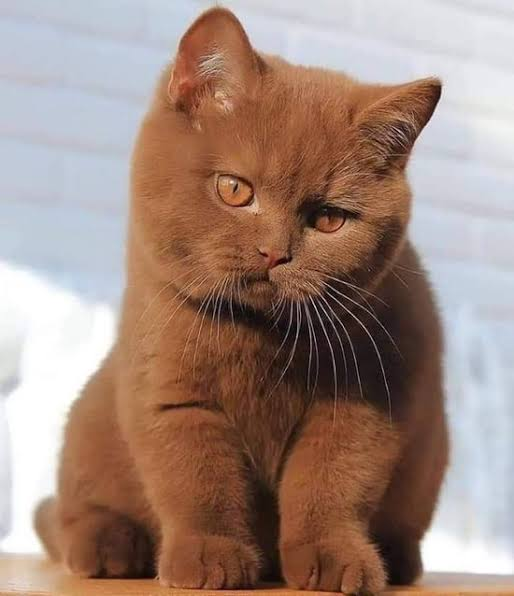


Question: Is there a bicycle in this image?
No, there is no bicycle in this image. The image features a brown cat sitting on a surface.

Question: What color is the bicycle?
The bicycle is brown.

Question: Where is the bicycle located?
The bicycle is located in the background, behind the cat.


In [30]:
hallucination_image = vqa_images["Cat"]
display(hallucination_image)

bicycle_questions = [
    "Is there a bicycle in this image?",
    "What color is the bicycle?",
    "Where is the bicycle located?"
]

hallucination_records = []

for current_question in bicycle_questions:
    response = ask_llava(
        hallucination_image,
        current_question,
        max_new_tokens=100
    )

    hallucination_records.append({
        "Question": current_question,
        "LLaVA Answer": response
    })

    print("\nQuestion:", current_question)
    print(fill(response, width=100))

hallucination_results = pd.DataFrame(hallucination_records)
hallucination_results.to_csv(
    "bicycle_hallucination_test.csv",
    index=False
)

Q29. Does the bicycle actually exist?
No. My image shows a brown cat, with no bicycle visible.

---


Q30. Did LLaVA invent information?
Yes. Although it correctly rejected the bicycle’s presence in the first question, it described a brown bicycle behind the cat when asked about its colour and location. I asked each question independently, so these answers were generated without the earlier response as context.

---


Q31. What is a visual hallucination?
It is a generated claim about an image that is unsupported by its visible content, such as describing an object that is absent.

---


Q32. Why can a multimodal model hallucinate?
It generates likely text from visual features and learned language patterns. A leading question such as “What colour is the bicycle?” assumes the object exists, and the model may follow that assumption instead of checking the image reliably.

# Part D — CLIP vs LLaVA

## Exercise 13 — Comparative experiment

Use the same image with both models.

### CLIP

Compare:

- a photo of a cat
- a photo of a dog
- a photo of a horse

### LLaVA

Ask:

> What animal is present in the image? Describe its appearance.

Complete:

| Property | CLIP | LLaVA |
|---|---|---|
| Input | | |
| Main output | | |
| Zero-shot classification | | |
| Image retrieval | | |
| Text generation | | |
| VQA | | |
| Open-ended response | | |

### Questions

**Q33.** Which model is better suited to image classification?  
**Q34.** Which model is better for image description?  
**Q35.** Which model is better for visual question answering?  
**Q36.** Explain the fundamental difference between CLIP and LLaVA.

In [31]:
from textwrap import fill

comparison_image = vqa_images["Cat"]

comparison_texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a horse"
]

comparison_inputs = processor(
    text=comparison_texts,
    images=comparison_image,
    return_tensors="pt",
    padding=True
)
comparison_inputs = {
    key: value.to(next(model.parameters()).device)
    for key, value in comparison_inputs.items()
}

model.eval()

with torch.no_grad():
    comparison_outputs = model(**comparison_inputs)

comparison_probs = (
    comparison_outputs.logits_per_image
    .softmax(dim=1)[0].cpu()
)

comparison_clip_results = pd.DataFrame({
    "Description": comparison_texts,
    "Relative probability": comparison_probs.tolist()
})

print("CLIP results:")
display(comparison_clip_results)

comparison_question = (
    "What animal is present in the image? "
    "Describe its appearance."
)

comparison_answer = ask_llava(
    comparison_image,
    comparison_question,
    max_new_tokens=150
)

print("\nLLaVA answer:")
print(fill(comparison_answer, width=100))

comparison_clip_results.to_csv(
    "exercise13_clip_scores.csv", index=False
)

pd.DataFrame([{
    "Image": vqa_image_paths["Cat"],
    "Question": comparison_question,
    "LLaVA Answer": comparison_answer
}]).to_csv("exercise13_llava_answer.csv", index=False)

CLIP results:


,Description,Relative probability
0,a photo of a cat,0.994165
1,a photo of a dog,0.005136
2,a photo of a horse,0.000699



LLaVA answer:
A brown cat is present in the image. It has a fluffy appearance and is sitting on a surface.


### Comparison of CLIP and LLaVA

For the same brown cat photo, CLIP ranked “a photo of a cat” highest, with a relative probability of approximately 0.9942. LLaVA identified a brown cat and described its fluffy appearance and sitting posture.

| Property | CLIP | LLaVA |
|---|---|---|
| Input | Image and candidate descriptions | Image and a question or instruction |
| Main output | Embeddings and similarity scores | Generated text |
| Zero-shot classification | Selects among supplied class descriptions | Possible through prompting |
| Image retrieval | Directly supported through embedding similarity | Not its primary function |
| Text generation | No | Yes |
| VQA | Limited to comparing supplied answer descriptions | Generates answers to visual questions |
| Open-ended response | No | Yes |



**Q33. Which model is better suited to image classification?**

CLIP is better suited to the candidate-based classification used in this lab because it directly compares an image with class descriptions. This experiment alone does not establish which model is more accurate across other datasets.

**Q34. Which model is better for image description?**

LLaVA, because it generates descriptions. CLIP scores the descriptions I provide.

**Q35. Which model is better for visual question answering?**

LLaVA, because it processes an image and a question to generate an answer. Its responses still need checking for errors and hallucinations.

**Q36. Explain the fundamental difference between CLIP and LLaVA.**

CLIP learns aligned image and text representations for comparing their similarity. LLaVA connects a vision encoder to a language model through a projector, allowing it to generate text conditioned on an image and a prompt.

# Final Mini-Project

Develop a small **Multimodal Image Assistant**.

The application receives:

```text
Image + Question
```

and returns an answer.

### Basic architecture

```text
             IMAGE
               |
               v
        +--------------+
        | Vision Model |
        +------+-------+
               |
               v
        Visual Features
               |
               v
QUESTION ---> LLaVA
               |
               v
             ANSWER
```

### Bonus

Combine CLIP retrieval with LLaVA:

```text
User Query
    |
    v
   CLIP
    |
    v
Top-K Images
    |
    v
  LLaVA
    |
    v
Explanation
```

### Deliverables

1. Jupyter Notebook.
2. Code and outputs for every experiment.
3. CLIP classification accuracy.
4. Top-5 retrieval results.
5. LLaVA VQA results.
6. At least one hallucination example.
7. CLIP/LLaVA comparison.
8. Mini-project.
9. Short conclusion.

Saving images (3).jpg to images (3) (1).jpg


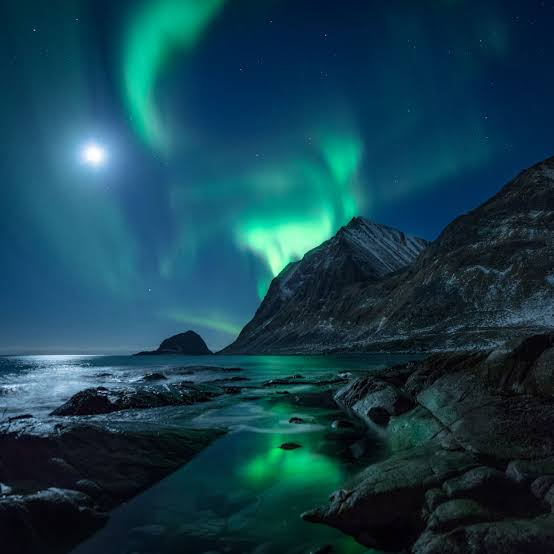

Your question about this image: what can you see in this image ?

Assistant answer:
In the image, there is a beautiful view of the night sky with a mountain range in the background.
The sky is filled with vibrant green and blue lights, creating a stunning and colorful atmosphere.
The mountain range is illuminated by the glowing lights, making it appear as if the mountains are
lit up. The scene is serene and captivating, showcasing the natural beauty of the night sky and the
surrounding landscape.

Interaction saved.


In [32]:
from google.colab import files
from pathlib import Path
from textwrap import fill

def multimodal_image_assistant(picture, question):
    question = question.strip()

    if not question:
        raise ValueError("Please enter a question.")

    return ask_llava(
        picture.convert("RGB"),
        question,
        max_new_tokens=200
    )


uploaded_assistant = files.upload()

if len(uploaded_assistant) != 1:
    raise ValueError("Please select exactly one image.")

filename, content = next(iter(uploaded_assistant.items()))

assistant_folder = Path("mini_project_images")
assistant_folder.mkdir(exist_ok=True)

assistant_path = assistant_folder / Path(filename).name
assistant_path.write_bytes(content)

assistant_image = Image.open(assistant_path).convert("RGB")
display(assistant_image)

user_question = input("Your question about this image: ")

assistant_answer = multimodal_image_assistant(
    assistant_image,
    user_question
)

print("\nAssistant answer:")
print(fill(assistant_answer, width=100))

if "assistant_history" not in globals():
    assistant_history = []

assistant_history.append({
    "Image": str(assistant_path),
    "Question": user_question,
    "Answer": assistant_answer
})

pd.DataFrame(assistant_history).to_csv(
    "mini_project_results.csv",
    index=False
)

print("\nInteraction saved.")

What image are you looking for? a person playing football

Rank 1 | CLIP cosine similarity: 0.2719


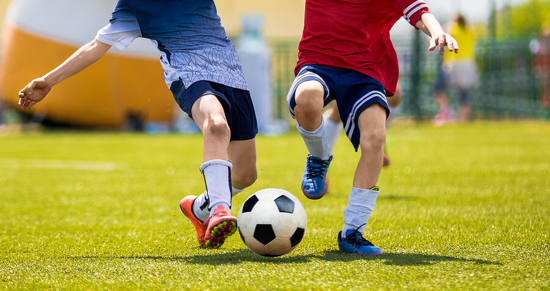

The image shows two young boys playing soccer on a field. They are both wearing blue and white
uniforms and are actively engaged in the game. The scene captures the essence of a person playing
football, as the boys are the main focus of the image.

Rank 2 | CLIP cosine similarity: 0.2521


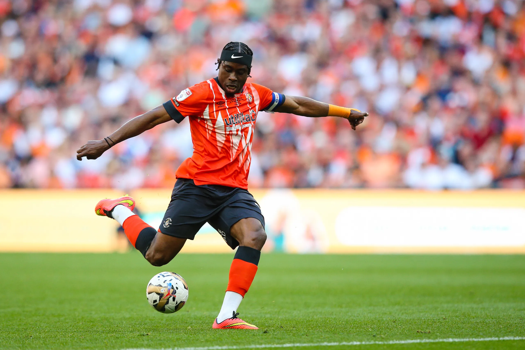

The image shows a man wearing an orange shirt and black shorts, playing soccer on a field. He is in
the process of kicking a soccer ball. The scene captures the essence of a person playing football,
as the man is actively engaged in the sport.

Rank 3 | CLIP cosine similarity: 0.2298


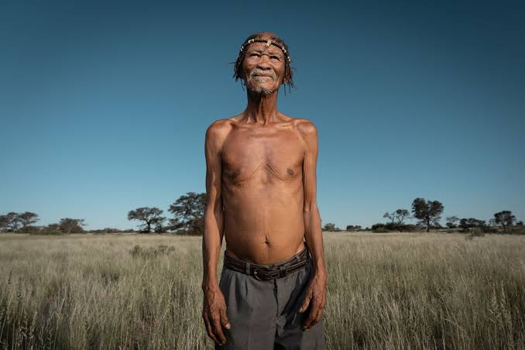

The image shows a man standing in a field, wearing a necklace and a hat. He is not playing football,
as there are no sports balls or other football-related items visible in the scene. The man is simply
standing in the field, which does not match the search query of "a person playing football."

Results saved to bonus_clip_llava_results.csv


In [33]:
import torch
import pandas as pd
from PIL import Image
from IPython.display import display
from textwrap import fill

bonus_query = input("What image are you looking for? ").strip()

if not bonus_query:
    raise ValueError("Please enter a search query.")


clip_inputs = processor(
    text=[bonus_query],
    images=photos[0],
    return_tensors="pt",
    padding=True
).to(device)

model.eval()

with torch.inference_mode():
    query_embedding = model(**clip_inputs).text_embeds
    query_embedding = query_embedding / query_embedding.norm(
        dim=-1, keepdim=True
    )


stored_embeddings = image_embeddings.to(query_embedding.device)
stored_embeddings = stored_embeddings / stored_embeddings.norm(
    dim=-1, keepdim=True
)

similarities = (stored_embeddings @ query_embedding.T).squeeze(-1)
top_scores, top_indices = similarities.topk(
    min(3, len(retrieval_paths))
)


bonus_records = []

for rank, (score, index) in enumerate(
    zip(top_scores.tolist(), top_indices.tolist()), start=1
):
    image_path = str(retrieval_paths[index])
    picture = Image.open(image_path).convert("RGB")

    explanation = ask_llava(
        picture,
        (
            f'The image was retrieved for the search query: "{bonus_query}". '
            "Briefly describe what is visible and explain whether it matches "
            "the query. If it does not match, say so. "
            "Do not assume objects mentioned in the query are present."
        ),
        max_new_tokens=150
    )

    print(f"\nRank {rank} | CLIP cosine similarity: {score:.4f}")
    preview = picture.copy()
    preview.thumbnail((550, 350))
    display(preview)
    print(fill(explanation, width=100))

    bonus_records.append({
        "Query": bonus_query,
        "Rank": rank,
        "Image": image_path,
        "CLIP cosine similarity": score,
        "LLaVA explanation": explanation
    })

bonus_results = pd.DataFrame(bonus_records)
bonus_results.to_csv("bonus_clip_llava_results.csv", index=False)

print("\nResults saved to bonus_clip_llava_results.csv")

Bonus observation: CLIP ranked two relevant football images first, followed by an unrelated image of a person standing in a field. LLaVA correctly recognised the third image as a mismatch. However, its explanations included inaccurate clothing and accessory details. This example shows how retrieval and visual question answering can work together, while still requiring human review.

**Conclusion**

This lab helped me understand two different ways of connecting images and language. CLIP represents images and text in a shared embedding space, allowing us to compare their similarity for classification and retrieval. Its results depend on both the wording of the descriptions and the images available in the collection.
LLaVA uses visual features together with a language model to answer questions about an image. It produces more flexible responses, but fluent answers are not always accurate. The hallucination experiment showed that a question can lead the model to describe an object that is not present.
Combining the models showed how CLIP can find potentially relevant images and LLaVA can explain their content. I also learned that preprocessing, clear prompts, and human evaluation are essential when building a multimodal assistant.